# Ab initio dynamics with PySCF TDA

Run **mean-field (Ehrenfest)** and **fewest-switches surface hopping (FSSH)** dynamics for LiH with the restricted PBE ground state and its first singlet TDA excited state in STO-3G.

The starting conditions match the CASSCF and CMS-PDFT notebooks: the same CASSCF S0 Wigner distribution, isotope masses, 100 seeds, outward stretch impulse, and pure S1 electronic state. Both algorithms propagate 100 trajectories for 100 a.u. with a 1 a.u. time step. The default two-state space `[S0, S1]` gives the closest comparison with those notebooks. Only the electronic structure method used during dynamics changes.

The current TDDFT implementation uses the **Tamm–Dancoff approximation (TDA)**. Full TDDFT (`tda=False`) is unsupported. Select `xc="b3lyp"` to compare the other supported functional. The impulse supplies additional energy independently of the sampling temperature; this is an energetic demonstration rather than an equilibrium preparation. The full ensemble performs many electronic calculations.

## 1. Prepare the environment

From the **repository root**, install the package and notebook dependencies into the environment selected as this notebook's kernel:

```bash
python -m pip install -e '.[pyscf]' matplotlib ipykernel
```

Select that environment in a Jupyter-capable editor and run the cells in order. The calculator uses PySCF 2.14.x; Q-Chem and ASE are not required. Run All does not install packages.

In [6]:
import os
import copy
import warnings
from time import perf_counter

for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(variable, "1")

import numpy as np
import matplotlib.pyplot as plt
import pyscf

from qclab import Simulation
from qclab.algorithms import MeanFieldAbInitio, FewestSwitchesSurfaceHoppingAbInitio
from qclab.dynamics import serial_driver
from qclab.functions import z_to_q, z_to_p, qp_to_z
from qclab.interfaces import QCLabPySCFInterface
from qclab.models import AbInitio
from qclab.numerical_constants import (
    AMU_TO_EMASS, ANGSTROM_TO_BOHR, AU_TIME_TO_FS, INVCM_TO_HA, HA_TO_EV, K_B_HA_PER_K,
)

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
warnings.filterwarnings(
    "ignore", message="OpenMP is not available.*", category=UserWarning,
    module=r"pyscf\.lib\.misc",
)
print("PySCF version:", pyscf.__version__)

PySCF version: 2.14.0


## 2. Select the functional and molecule

All inputs use atomic units: positions in Bohr, masses in electron masses, energy in Hartree, and propagation time in atomic units. The reference bond is 3 Bohr (about 1.59 Angstrom), with lithium-7 and hydrogen-1 masses.

The dynamics calculator uses a closed-shell restricted Kohn–Sham reference (`multiplicity=1`) and singlet excited states (`excited_multiplicity=1`). `num_quantum_states=2` includes the ground state; `excited_state_indices=[0]` selects the first excited response root, so returned slots are `[S0, S1]`.

TDA uses the occupied and virtual orbital response space. **Do not supply CASSCF active-space or state-averaging arguments in this dynamics configuration.** The separate CASSCF calculator in section 3 is used only to obtain identical nuclear samples. TDA and CASSCF/CMS-PDFT describe different electronic models, so matching starting conditions does not imply matching forces, populations, or hop times.

In [7]:
xc = "pbe"  # Alternative: "b3lyp". Rerun subsequent cells after changing.
atom_names = ["Li", "H"]
atom_positions = np.array([[0.0, 0.0, 0.0], [0.0, 0.0, 3.0]])  # Bohr.
atom_masses = np.array([7.0160034366, 1.00782503223]) * AMU_TO_EMASS
num_quantum_states = 2
state_labels = ["S0", "S1"]

calculator_args = {
    "method_es": "tddft",
    "tda": True,
    "xc": xc,
    "basis": "sto-3g",
    "charge": 0,
    "multiplicity": 1,
    "excited_multiplicity": 1,
    "excited_state_indices": [0],
    "use_etfs": True,
    "grids_level": 5,
    "num_threads": 1,
    "max_memory": 1000,
    "scf_options": {"conv_tol": 1e-12},
    "td_options": {"conv_tol": 1e-11},
}
print("Dynamics method: %s / TDA / STO-3G" % xc.upper())
print("Returned states:", state_labels)
print("Reference bond: %.4f Angstrom" % (3.0 / ANGSTROM_TO_BOHR))

Dynamics method: PBE / TDA / STO-3G
Returned states: ['S0', 'S1']
Reference bond: 1.5875 Angstrom


## 3. Use the CASSCF reference modes for identical Wigner samples

The other PySCF notebooks sample the S0 **equal-weight, two-singlet SA-CASSCF(2,2)** harmonic Wigner distribution. We use that exact reference model and its convergence settings here. Recomputing the modes with PBE or B3LYP would change the initial positions and momenta even for identical random seeds.

`normal_modes(state_ind=0, delta=1e-3)` removes translations and rotations and returns one mass-weighted LiH stretch. We fix its H-z component positive, exactly as in the CASSCF and CMS-PDFT notebooks. The sampling reference always contains **two states**, independently of the number of TDA states requested for dynamics. Its normal modes remain fixed when `xc` changes; propagation uses the selected TDA functional.

In [8]:
# Match the CASSCF notebook's sampling model, including its tolerances.
sampling_calculator_args = {
    "method_es": "casscf",
    "basis": "sto-3g",
    "charge": 0,
    "multiplicity": 1,
    "ncas": 2,
    "nelecas": 2,
    "num_threads": 1,
    "max_memory": 1000,
    "scf_options": {"conv_tol": 1e-10},
    "casscf_options": {
        "conv_tol": 1e-9,
        "conv_tol_grad": 1e-6,
        "ah_conv_tol": 1e-14,
    },
}
reference_calculator = QCLabPySCFInterface(
    atom_positions=atom_positions,
    atom_masses=atom_masses,
    atom_names=atom_names,
    num_quantum_states=2,  # Keep the two-state SA-CASSCF sampling model fixed.
    **sampling_calculator_args,
)
start = perf_counter()
vibrations = reference_calculator.normal_modes(state_ind=0, delta=1e-3)
frequencies = vibrations["harmonic_frequency"]
modes = vibrations["normal_mode"]
if modes[5, 0] < 0:
    modes *= -1

assert vibrations["normal_mode_convention"] == "mass_weighted"
assert frequencies.shape == (1,) and modes.shape == (6, 1)
assert np.isrealobj(frequencies) and np.all(np.isfinite(frequencies)) and np.all(frequencies > 0)
np.testing.assert_allclose(modes.T @ modes, np.eye(1), atol=1e-8)
print("CASSCF sampling frequency (cm^-1):", frequencies / INVCM_TO_HA)
print("Normal-mode calculation: %.2f s" % (perf_counter() - start))

CASSCF sampling frequency (cm^-1): [1669.70061343]
Normal-mode calculation: 0.67 s


## 4. Match the kicked Wigner initial conditions and S1 state

At `temperature_K=0`, Wigner sampling retains zero-point widths in both positions and momenta. With orthonormal mass-weighted modes $U$, QC Lab uses

$$q=q_0+M^{-1/2}UQ,\qquad p=M^{1/2}UP.$$

As in the CASSCF and CMS-PDFT notebooks, add an outward **0.03 Bohr/a.u. relative stretch velocity**. The equal and opposite impulses preserve the initial center-of-mass momentum. Their nominal energy is about 19.7 eV; the sampled kinetic-energy increase includes a cross term with the Wigner momentum.

The executable starting conditions are matched here: `seeds=np.arange(100)`, 100 trajectories, 100 a.u. propagation, `dt_update=dt_collect=1.0`, and initial electronic amplitudes `[0.0, 1.0]` (pure S1). With the same sampling reference and eigenvector sign, the initial Cartesian positions and momenta match for every seed.

Set **`temperature_K`** in the next cell; it is converted to the model's `kBT` in Hartree. For example, 10 K corresponds to `kBT=3.1668e-5`, and 300 K to approximately `0.000950`. Setting `kBT=10` directly would mean about **3.16 million kelvin**, which produces extreme geometries outside this harmonic sampling model.

The stretch impulse is additional energy, independent of temperature. For a thermal initial ensemble without this excitation, set `stretch_velocity_kick=0.0` in all notebooks being compared.

In [9]:
settings = {
    "num_trajs": 4,
    "batch_size": 4,
    "tmax": 100.0,
    "dt_update": 1.0,
    "dt_collect": 1.0,
    "progress_bar": True,
}
seeds = np.arange(settings["num_trajs"], dtype=int)
initial_electronic_state = 1  # Zero-based: 0 = S0, 1 = S1.
stretch_velocity_kick = 0.03  # Added relative nuclear velocity, Bohr / a.u. of time.
reduced_mass = np.prod(atom_masses) / np.sum(atom_masses)
wf_initial = np.zeros(num_quantum_states, dtype=complex)
wf_initial[initial_electronic_state] = 1.0
temperature_K = 0.0  # Kelvin. Set to 10.0 for 10 K or 300.0 for 300 K.
if not np.isfinite(temperature_K) or temperature_K < 0:
    raise ValueError("temperature_K must be finite and nonnegative.")

model_constants = {
    "calculator": "pyscf",
    "calculator_args": calculator_args,
    "atom_names": atom_names,
    "atom_positions": atom_positions,
    "atom_masses": atom_masses,
    "num_quantum_states": num_quantum_states,
    "kBT": temperature_K * K_B_HA_PER_K,  # Internal thermal energy in Hartree.
    **vibrations,
}
np.testing.assert_allclose(np.vdot(wf_initial, wf_initial), 1.0)
print("Seeds:", seeds)
print("Propagation time: %.3f fs" % (settings["tmax"] * AU_TIME_TO_FS))
print("Sampling temperature: %.1f K; kBT = %.8g Hartree" % (
    temperature_K, model_constants["kBT"]
))
print("Nominal stretch-impulse energy: %.2f eV" % (
    0.5 * reduced_mass * stretch_velocity_kick**2 * HA_TO_EV
))

def init_kicked_wigner(model, parameters, **kwargs):
    """Sample full-width Wigner coordinates, then add a COM-preserving impulse."""
    z = AbInitio.init_classical(model, parameters, **kwargs)
    mass = model.constants.classical_coordinate_mass
    weight = model.constants.classical_coordinate_weight
    q = z_to_q(z, mass, weight).reshape((-1, 2, 3))
    p = z_to_p(z, mass, weight).reshape((-1, 2, 3))
    bond = q[:, 1] - q[:, 0]
    direction = bond / np.linalg.norm(bond, axis=1)[:, None]
    impulse = reduced_mass * stretch_velocity_kick * direction
    p[:, 0] -= impulse
    p[:, 1] += impulse
    return qp_to_z(q.reshape((-1, 6)), p.reshape((-1, 6)), mass, weight)


# Preview the same kicked Wigner samples that initialize each dynamics run.
preview_model = AbInitio(copy.deepcopy(model_constants))
z_initial = init_kicked_wigner(preview_model, {}, seed=seeds)
masses = preview_model.constants.classical_coordinate_mass[np.newaxis, :]
weights = preview_model.constants.classical_coordinate_weight[np.newaxis, :]
q_initial = z_to_q(z_initial, masses, weights).reshape(len(seeds), len(atom_names), 3)
p_initial = z_to_p(z_initial, masses, weights).reshape(len(seeds), len(atom_names), 3)
bond_lengths = np.linalg.norm(q_initial[:, 1] - q_initial[:, 0], axis=1) / ANGSTROM_TO_BOHR

assert np.all(np.isfinite(z_initial))
np.testing.assert_allclose(p_initial.sum(axis=1), 0.0, atol=1e-10)
print("Seed   Li-H distance (Angstrom)   H momentum along z (a.u.)")
for seed, distance, momentum in zip(seeds, bond_lengths, p_initial[:, 1, 2]):
    print("%4d   %22.6f   %27.6f" % (seed, distance, momentum))

Seeds: [0 1 2 3]
Propagation time: 2.419 fs
Sampling temperature: 0.0 K; kBT = 0 Hartree
Nominal stretch-impulse energy: 19.67 eV
Seed   Li-H distance (Angstrom)   H momentum along z (a.u.)
   0                 1.776351                     49.181170
   1                 1.761397                     46.679785
   2                 1.542923                     48.052919
   3                 1.778981                     49.271032


## 5. Run both algorithms

Each run gets a fresh model and algorithm, the same `init_kicked_wigner` initializer, and the same pure S1 amplitudes in **`initial_state["wf_adb"]`**. The normal modes are computed once and reused. The dynamics calculator is TDA; the sampling reference remains SA-CASSCF for the method comparison.

Mean field propagates under the electronic mean force. FSSH propagates on an active surface and uses stochastic hopping decisions and energy-conserving momentum rescaling. Its electronic propagation uses wavefunction overlaps. Both drivers return ensemble-averaged observables.

The diagnostic tasks below check finite coordinates and electronic amplitudes, and check each trajectory's electronic norm at collection times. They record the absolute norm error without modifying the dynamics or drawing random numbers.
If ordinary RKS SCF iterations stall, the calculator makes one bounded Newton SCF retry with the same functional, grid, and convergence tolerances. Each attempt uses the configured iteration limit. Unresolved failures report the trajectory seed and geometry; no unconverged reference or response is accepted.


In [10]:
def update_electronic_diagnostics(
    sim, state, parameters, wf_name="wf_adb", z_name="z", error_name="electronic_norm_error",
):
    """Compute a diagnostic without changing coordinates or amplitudes."""
    wavefunction = np.asarray(state[wf_name])
    if not np.all(np.isfinite(wavefunction)) or not np.all(np.isfinite(state[z_name])):
        raise RuntimeError("The trajectory contains nonfinite coordinates or electronic amplitudes.")
    norm = np.sum(np.abs(wavefunction)**2, axis=-1)
    np.testing.assert_allclose(norm, 1.0, atol=1e-7, rtol=0)
    state[error_name] = np.abs(norm - 1.0)
    return state, parameters


def collect_electronic_diagnostics(
    sim, state, parameters, error_name="electronic_norm_error",
    output_name="electronic_norm_error",
):
    state["output_dict"][output_name] = state[error_name].copy()
    return state, parameters


def make_simulation(algorithm_class):
    sim = Simulation(copy.deepcopy(settings))
    sim.model = AbInitio(copy.deepcopy(model_constants))
    sim.model.ingredients = sim.model.ingredients + [("init_classical", init_kicked_wigner)]
    sim.algorithm = algorithm_class()
    sim.algorithm.collect_recipe = sim.algorithm.collect_recipe + [
        update_electronic_diagnostics, collect_electronic_diagnostics,
    ]
    sim.initial_state["wf_adb"] = wf_initial.copy()
    return sim


start = perf_counter()
mean_field_data = serial_driver(make_simulation(MeanFieldAbInitio), seeds=seeds.copy())
print("Mean field: %.2f s" % (perf_counter() - start))
start = perf_counter()
fssh_data = serial_driver(make_simulation(FewestSwitchesSurfaceHoppingAbInitio), seeds=seeds.copy())
print("FSSH: %.2f s" % (perf_counter() - start))

100%|██████████| 101/101 [05:27<00:00,  3.25s/it]


Mean field: 327.89 s


100%|██████████| 101/101 [05:30<00:00,  3.27s/it]

FSSH: 330.43 s


## 6. Plot adiabatic populations

Both results contain `data_dict["dm_adb"]`, but their diagonal estimators differ:

- **Mean field:** ensemble-averaged electronic populations $|c_i|^2$.
- **Stochastic FSSH:** fractions of trajectories on the active surfaces.

Both start entirely on S1. With 100 trajectories, an individual accepted hop changes an FSSH surface fraction by 0.01. Identical initial conditions do not require the two methods or algorithms to predict identical populations or hop times. The first figure shows the full populations; the second shows transfer to the initially unoccupied S0 state.

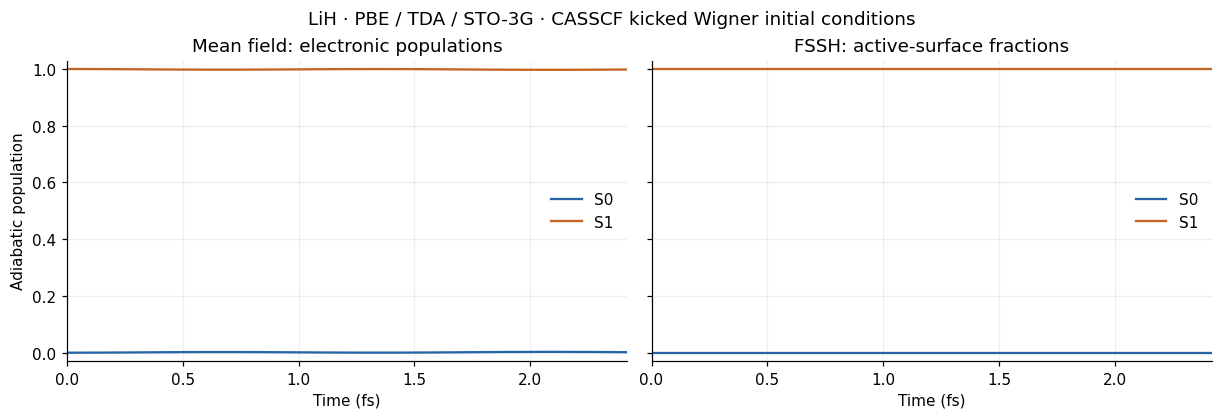

In [11]:
def population_series(data):
    time_fs = np.asarray(data.data_dict["t"]) * AU_TIME_TO_FS
    populations = np.diagonal(np.asarray(data.data_dict["dm_adb"]), axis1=-2, axis2=-1).real.copy()
    assert populations.shape == (len(time_fs), num_quantum_states)
    assert np.all(np.isfinite(populations))
    np.testing.assert_allclose(populations.sum(axis=1), 1.0, atol=1e-7)
    assert np.all(populations >= -1e-7) and np.all(populations <= 1.0 + 1e-7)
    return time_fs, populations

mf_time, mf_pop = population_series(mean_field_data)
fssh_time, fssh_pop = population_series(fssh_data)
np.testing.assert_allclose(mf_time, fssh_time)
np.testing.assert_array_equal(mean_field_data.data_dict["seed"], fssh_data.data_dict["seed"])

colors = ["#2764a5", "#c46621"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7), sharex=True, sharey=True, constrained_layout=True)
for state in range(num_quantum_states):
    axes[0].plot(mf_time, mf_pop[:, state], color=colors[state], label=state_labels[state])
    axes[1].step(fssh_time, fssh_pop[:, state], where="post", color=colors[state], label=state_labels[state])
axes[0].set_title("Mean field: electronic populations")
axes[1].set_title("FSSH: active-surface fractions")
axes[0].set_ylabel("Adiabatic population")
for ax in axes:
    ax.set_xlabel("Time (fs)")
    ax.set_xlim(mf_time[0], mf_time[-1])
    ax.set_ylim(-0.03, 1.03)
    ax.grid(alpha=0.2)
    ax.legend(frameon=False)
fig.suptitle("LiH · %s / TDA / STO-3G · CASSCF kicked Wigner initial conditions" % xc.upper())
plt.show()

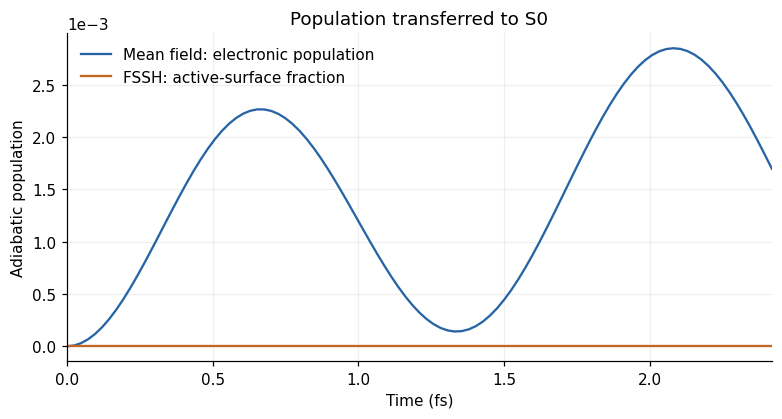

Mean field
  Final populations: [0.0016985 0.9983015]
  Maximum population-sum error: 3.775e-15
  Largest collected ensemble-mean |electronic norm - 1|: 1.193e-14
  Maximum total-energy change: 1.848e-05 Hartree
FSSH
  Final populations: [0. 1.]
  Maximum population-sum error: 0.000e+00
  Largest collected ensemble-mean |electronic norm - 1|: 1.063e-14
  Maximum total-energy change: 4.097e-06 Hartree


In [12]:
fig, ax = plt.subplots(figsize=(7, 3.7), constrained_layout=True)
ax.plot(mf_time, mf_pop[:, 0], label="Mean field: electronic population", color=colors[0])
ax.step(fssh_time, fssh_pop[:, 0], where="post",
        label="FSSH: active-surface fraction", color=colors[1])
ax.set(title="Population transferred to S0", xlabel="Time (fs)", ylabel="Adiabatic population")
ax.set_xlim(mf_time[0], mf_time[-1])
ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
ax.grid(alpha=0.2)
ax.legend(frameon=False)
plt.show()

for label, data, populations in (
    ("Mean field", mean_field_data, mf_pop),
    ("FSSH", fssh_data, fssh_pop),
):
    energy = np.real(data.data_dict["quantum_energy"] + data.data_dict["classical_energy"])
    norm_error = np.asarray(data.data_dict["electronic_norm_error"])
    assert np.all(np.isfinite(energy)) and np.all(np.isfinite(norm_error))
    print(label)
    print("  Final populations:", populations[-1])
    print("  Maximum population-sum error: %.3e" % np.max(np.abs(populations.sum(axis=1) - 1.0)))
    print("  Largest collected ensemble-mean |electronic norm - 1|: %.3e" % np.max(norm_error))
    print("  Maximum total-energy change: %.3e Hartree" % np.max(np.abs(energy - energy[0])))

## 7. Adapt the example

- Select `xc="b3lyp"` and rerun subsequent cells to compare the other supported functional. The CASSCF sampling reference stays fixed, so the same seeds retain identical starting positions and momenta.
- Keep the sampling reference, seeds, temperature, S1 amplitudes, and stretch impulse fixed when comparing electronic structure methods. Changing a sampling frequency or mode sign changes the coordinates associated with a seed.
- Set `temperature_K` to the desired nuclear sampling temperature in kelvin. The electronic calculation remains a zero-electronic-temperature calculation. Check the sampled bond range and time-step convergence when increasing temperature.
- Reduce trajectory count or propagation duration for a quick check. The saved configuration matches the other notebooks' full 100-trajectory, 100 a.u. runs. Check time-step and ensemble convergence for applications.
- Set `stretch_velocity_kick=0.0` to remove the additional impulse, changing all notebooks being compared.
- For an expanded singlet space, `num_quantum_states=3` with `excited_state_indices=[0, 3]` returns `[S0, S1, S4]`. At the reference LiH geometry, this selects the separated Sigma roots and skips the degenerate Pi roots 2 and 3. Update `state_labels`, the initial amplitude vector, and plot colors if making this change. Keep the **sampling calculator at two states**. The two-state default is the closest comparison with the CASSCF/CMS-PDFT examples.
- Response-root indices are energy ordered at each geometry. Phase alignment does not permute roots or guarantee electronic-character tracking through crossings. Exact same-spin degeneracies have no special treatment.
- `use_etfs=True` applies electron translation factors to derivative couplings. Overlaps remain ordinary many-electron overlaps, so their derivatives correspond to the uncorrected coupling convention (`use_etfs=False`). Coordinates, snapshots, and couplings use a consistent phase convention.
- Check SCF, TDA, analytic response, and numerical-grid convergence before interpreting results. PBE and B3LYP use finite atom-centered quadrature grids; denser radial and angular grids can be needed for quantitative orientation-independent results. Do not continue from an unconverged force.
- The supported TDA interface uses real restricted singlet references and one excited spin manifold. Full TDDFT, mixed excited multiplicities, spin-orbit coupling, frozen orbitals, density fitting, and other functionals are unsupported. CASSCF active-space and state-averaging options belong only in the separate sampling reference here.
- Save the averaged results with `mean_field_data.save("lih_tda_mean_field.h5")` and `fssh_data.save("lih_tda_fssh.h5")`.

The plots show populations over the full range and separately resolve transfer to S0; neither nonzero transfer nor an accepted hop is guaranteed. The energy diagnostic reports drift of the ensemble-averaged total energy. The electronic-norm diagnostic records ensemble-mean absolute errors, with every trajectory checked separately at collection times.

The derivative-coupling property contract uses inverse Angstrom, while coordinates and gradients use Bohr and Hartree/Bohr. QC Lab converts couplings to its internal coordinate convention automatically.